<a href="https://colab.research.google.com/github/kimj073/Mining-LULC-Africa/blob/main/MineWatch_IVC_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MineWatch IVC - artisanal mine segmentation from Sentinel-1/2 (Côte d'Ivoire)
**DSA4050_XA term paper · everything in one notebook: data → EDA → models → comparison → interactive dashboard**

**How to use:** Runtime → Change runtime type → **GPU**, then *Runtime → Run all*. Results are saved to Google Drive (`MyDrive/mining-asm-ivc/`), and finished models are cached, so after a disconnect just run all again.

| Part | Sections |
|---|---|
| (b) Data | 1-7 download, audit, band check, splits, EDA |
| (c) Models | 8-14 XGBoost baseline, U-Net / DeepLabV3+ runs, leaderboard, error analysis, spatial check |
| (d) Dashboard | 15-16 export + interactive dashboard |

**Smoke test first?** Set `QUICK_TEST = True` in section 8 (2 epochs on ~450 tiles, a few minutes, saved separately), confirm everything runs, then set it back to `False` for the real run.

In [1]:
import sys, subprocess, importlib.util, json, shutil, zipfile
from pathlib import Path
if importlib.util.find_spec("rasterio") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio"], check=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, rasterio
from rasterio.warp import transform as warp_transform
from IPython.display import display
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.cluster import KMeans

SEED = 4050
PIXEL_HA = 0.01                      # 10 m x 10 m pixel = 0.01 ha
np.random.seed(SEED)

try:                                  # Colab: keep results on Drive, big TIFFs on fast local disk
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/mining-asm-ivc")
    LOCAL_DIR = Path("/content/mining-data")
except ImportError:                   # laptop / lecturer's machine
    PROJECT_DIR, LOCAL_DIR = Path("./project"), Path("./mining-data")

DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
FIG_DIR = OUT_DIR / "figures"
for d in (DATA_DIR, OUT_DIR, FIG_DIR, LOCAL_DIR):
    d.mkdir(parents=True, exist_ok=True)

RECORD_ID, ZIP_NAME, EXPECTED_BYTES = "20747758", "IVC_tiles.zip", 1_814_722_369
print("results:", PROJECT_DIR, "| tiles on:", LOCAL_DIR)

Mounted at /content/drive
results: /content/drive/MyDrive/mining-asm-ivc | tiles on: /content/mining-data


## 1. Download the dataset (Zenodo) and extract the TIFFs
Both steps skip work that is already done, so re-running after a Colab restart is cheap.

In [3]:
ZIP_PATH = DATA_DIR / ZIP_NAME
if ZIP_PATH.exists() and ZIP_PATH.stat().st_size == EXPECTED_BYTES:
    print("Archive already downloaded.")
else:
    part = ZIP_PATH.with_suffix(".part"); part.unlink(missing_ok=True)
    url = f"https://zenodo.org/records/{RECORD_ID}/files/{ZIP_NAME}?download=1"
    with requests.get(url, stream=True, timeout=(30, 180)) as r:
        r.raise_for_status()
        got = 0
        with part.open("wb") as f:
            for chunk in r.iter_content(8 * 1024 * 1024):
                f.write(chunk); got += len(chunk)
    if got != EXPECTED_BYTES:
        part.unlink(missing_ok=True)
        raise RuntimeError(f"Size mismatch: got {got:,}, expected {EXPECTED_BYTES:,}. Re-run this cell.")
    part.replace(ZIP_PATH)
print("Archive:", ZIP_PATH, f"{ZIP_PATH.stat().st_size:,} bytes")

Archive: /content/drive/MyDrive/mining-asm-ivc/data/IVC_tiles.zip 1,814,722,369 bytes


In [4]:
with zipfile.ZipFile(ZIP_PATH) as zf:
    bad = zf.testzip()
    assert bad is None, f"Corrupt ZIP member: {bad}"
    tifs = [i for i in zf.infolist() if i.filename.lower().endswith((".tif", ".tiff"))]
    need = [i for i in tifs if not (LOCAL_DIR / i.filename).exists()
            or (LOCAL_DIR / i.filename).stat().st_size != i.file_size]
    free = shutil.disk_usage(LOCAL_DIR).free
    assert sum(i.file_size for i in need) < 0.9 * free, "Not enough local disk space to extract"
    for i in tqdm(need, desc="extracting"):
        dest = LOCAL_DIR / i.filename
        dest.parent.mkdir(parents=True, exist_ok=True)
        with zf.open(i) as src, dest.open("wb") as dst:
            shutil.copyfileobj(src, dst)
print(f"{len(tifs):,} TIFFs in archive, {len(need):,} extracted this run")

extracting:   0%|          | 0/6604 [00:00<?, ?it/s]

6,604 TIFFs in archive, 6,604 extracted this run


## 2. Pair images with masks and audit every mask
Checks: every image has a mask (and vice versa), exactly 12 bands, same tile size, labels only 0/1, how many pixels are nodata.

In [5]:
image_by_key = {(p.parent.parent.name, p.stem.replace("IMG_", "")): p
                for p in LOCAL_DIR.glob("data/IVC_tiles/*/IMAGE/IMG_*.tif")}
mask_by_key = {(p.parent.parent.name, p.stem.replace("MASK_", "")): p
               for p in LOCAL_DIR.glob("data/IVC_tiles/*/MASK/MASK_*.tif")}
print(f"images {len(image_by_key):,} | masks {len(mask_by_key):,} | "
      f"images without mask {len(set(image_by_key) - set(mask_by_key))} | "
      f"masks without image {len(set(mask_by_key) - set(image_by_key))}")
keys = sorted(set(image_by_key) & set(mask_by_key))

rows, odd_labels, shapes, band_counts, nodata_px = [], 0, set(), set(), 0
for key in tqdm(keys, desc="auditing"):
    with rasterio.open(mask_by_key[key]) as m:
        mk = m.read(1, masked=True)
    with rasterio.open(image_by_key[key]) as s:
        b, crs = s.bounds, str(s.crs)
        shapes.add((s.height, s.width)); band_counts.add(s.count)
    vals = np.unique(mk.compressed())
    odd_labels += int(not set(vals.tolist()) <= {0, 1})
    nodata_px += int(np.ma.getmaskarray(mk).sum())
    rows.append(dict(
        tile_id=f"{key[0]}_{key[1]}", zone=key[0],
        image_rel=str(image_by_key[key].relative_to(LOCAL_DIR)),
        mask_rel=str(mask_by_key[key].relative_to(LOCAL_DIR)),
        positive_pixels=int((mk.compressed() == 1).sum()), valid_pixels=int(mk.count()),
        minx=b.left, miny=b.bottom, maxx=b.right, maxy=b.top, crs=crs))

assert band_counts == {12}, f"Expected 12 bands, found {band_counts}"
assert len(shapes) == 1, f"Tiles differ in size: {shapes}"
assert odd_labels == 0, f"{odd_labels} masks contain labels other than 0/1"
print("tile size:", shapes.pop(), "| bands: 12 | nodata mask pixels:", f"{nodata_px:,}")
tiles = pd.DataFrame(rows)
tiles["has_positive"] = (tiles.positive_pixels > 0).astype(int)
tiles["positive_fraction"] = tiles.positive_pixels / tiles.valid_pixels

images 3,302 | masks 3,302 | images without mask 0 | masks without image 0


auditing:   0%|          | 0/3302 [00:00<?, ?it/s]

tile size: (128, 128) | bands: 12 | nodata mask pixels: 0


## 3. Verify the band order (do not skip)
Your first notebook named Band 0 = B1 but displayed bands `[2,1,0]` as RGB, which contradicts that naming. Here the order is read from the file metadata. **If the printed descriptions are empty, open the Zenodo README for record 20747758 and set `BAND_NAMES_OVERRIDE` below.**

In [6]:
with rasterio.open(image_by_key[keys[0]]) as src:
    desc = list(src.descriptions)
print("Band descriptions stored in the TIFF:", desc)

BAND_NAMES_OVERRIDE = None   # e.g. ["B2","B3","B4","B5","B6","B7","B8","B8A","B11","B12","S1_VV","S1_VH"]
FALLBACK = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "S1_VV", "S1_VH"]

if BAND_NAMES_OVERRIDE:
    BAND_NAMES, source = list(BAND_NAMES_OVERRIDE), "override"
elif all(desc):
    BAND_NAMES, source = desc, "TIFF metadata"
else:
    BAND_NAMES, source = FALLBACK, "UNVERIFIED fallback"
    print("\nWARNING: no band descriptions in the file. The order below is an ASSUMPTION - confirm it in the Zenodo README.")
assert len(BAND_NAMES) == 12
print(f"\nBand names ({source}):")
for i, n in enumerate(BAND_NAMES):
    print(f"  {i:2d}  {n}")

def find_band(*aliases):
    low = [n.lower() for n in BAND_NAMES]
    for a in aliases:
        if a.lower() in low:
            return low.index(a.lower())
    raise ValueError(f"Band {aliases} not found in {BAND_NAMES}; set BAND_NAMES_OVERRIDE")

TRUE_COLOUR = [find_band("B4"), find_band("B3"), find_band("B2")]          # R, G, B
SWIR_FALSE  = [find_band("B11"), find_band("B8"), find_band("B4")]
RADAR_IDX   = [i for i, n in enumerate(BAND_NAMES) if "s1" in n.lower() or n.lower() in ("vv", "vh")]
OPTICAL_IDX = [i for i in range(12) if i not in RADAR_IDX]
print("\nTrue-colour band indices (R,G,B):", TRUE_COLOUR, "| optical:", OPTICAL_IDX, "| radar:", RADAR_IDX)

Band descriptions stored in the TIFF: [None, None, None, None, None, None, None, None, None, None, None, None]


Band names (UNVERIFIED fallback):
   0  B1
   1  B2
   2  B3
   3  B4
   4  B5
   5  B6
   6  B7
   7  B8
   8  B8A
   9  B11
  10  S1_VV
  11  S1_VH

True-colour band indices (R,G,B): [3, 2, 1] | optical: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | radar: [10, 11]


## 4. Tile locations and the two splits
**Random split**: stratified 60/20/20 on tile level (as before). **Spatial split**: tiles are grouped into geographic blocks (k-means on location) and whole blocks go to train / validation / test, so test areas are not next to training areas. Both are saved; the training notebook reports both.

In [7]:
# tile centre in lon/lat (needed for the map and for spatial blocks)
tiles["lon"] = np.nan; tiles["lat"] = np.nan
for crs, g in tiles.groupby("crs"):
    cx, cy = ((g.minx + g.maxx) / 2).tolist(), ((g.miny + g.maxy) / 2).tolist()
    lon, lat = warp_transform(crs, "EPSG:4326", cx, cy)
    tiles.loc[g.index, "lon"], tiles.loc[g.index, "lat"] = lon, lat

# random stratified 60/20/20
tr_i, rest_i = train_test_split(tiles.index, test_size=0.4, stratify=tiles.has_positive, random_state=SEED)
va_i, te_i = train_test_split(rest_i, test_size=0.5, stratify=tiles.loc[rest_i, "has_positive"], random_state=SEED)
tiles["split_random"] = "train"
tiles.loc[va_i, "split_random"] = "val"; tiles.loc[te_i, "split_random"] = "test"

# spatial blocks -> StratifiedGroupKFold keeps each block in one split and balances positives
n_blocks = max(10, min(40, len(tiles) // 25))
tiles["block"] = KMeans(n_clusters=n_blocks, n_init=10, random_state=SEED).fit_predict(tiles[["lon", "lat"]])
folds = [idx for _, idx in StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
         .split(tiles, tiles.has_positive, tiles.block)]
tiles["split_spatial"] = "train"
tiles.loc[tiles.index[folds[0]], "split_spatial"] = "test"
tiles.loc[tiles.index[folds[1]], "split_spatial"] = "val"

def neighbour_leak(df, col):
    # share of test tiles whose footprint touches/overlaps a training tile (same CRS)
    touching = total = 0
    for crs, g in df.groupby("crs"):
        a = g[g[col] == "test"][["minx", "miny", "maxx", "maxy"]].to_numpy()
        b = g[g[col] == "train"][["minx", "miny", "maxx", "maxy"]].to_numpy()
        if len(a) == 0 or len(b) == 0:
            total += len(a); continue
        hit = ((a[:, None, 0] <= b[None, :, 2]) & (a[:, None, 2] >= b[None, :, 0]) &
               (a[:, None, 1] <= b[None, :, 3]) & (a[:, None, 3] >= b[None, :, 1])).any(1)
        touching += int(hit.sum()); total += len(a)
    return touching / max(total, 1)

summary = []
for col in ("split_random", "split_spatial"):
    ct = pd.crosstab(tiles[col], tiles.has_positive)
    summary.append(dict(split=col, train=int((tiles[col] == "train").sum()), val=int((tiles[col] == "val").sum()),
                        test=int((tiles[col] == "test").sum()),
                        test_tiles_touching_train=f"{neighbour_leak(tiles, col):.1%}"))
display(pd.DataFrame(summary))
print("Positive / negative tiles per split (random):"); display(pd.crosstab(tiles.split_random, tiles.has_positive))
print("Positive / negative tiles per split (spatial):"); display(pd.crosstab(tiles.split_spatial, tiles.has_positive))

,split,train,val,test,test_tiles_touching_train
0,split_random,1981,660,661,99.5%
1,split_spatial,1924,749,629,20.8%


Positive / negative tiles per split (random):


has_positive,0,1
split_random,,
test,539,122
train,1616,365
val,539,121


Positive / negative tiles per split (spatial):


has_positive,0,1
split_spatial,,
test,499,130
train,1575,349
val,620,129


## 5. Normalisation statistics (training tiles only, nodata ignored)

In [8]:
sample = tiles[tiles.split_random == "train"].sample(min(256, (tiles.split_random == "train").sum()), random_state=SEED)
s1 = np.zeros(12); s2 = np.zeros(12); cnt = np.zeros(12)
for rel in tqdm(sample.image_rel, desc="band statistics"):
    with rasterio.open(LOCAL_DIR / rel) as src:
        a = src.read(masked=True).astype(np.float64)
    ok = ~np.ma.getmaskarray(a); v = a.filled(0)
    s1 += np.where(ok, v, 0).sum((1, 2)); s2 += np.where(ok, v ** 2, 0).sum((1, 2)); cnt += ok.sum((1, 2))
band_mean = s1 / cnt
band_std = np.sqrt(np.maximum(s2 / cnt - band_mean ** 2, 1e-6))
display(pd.DataFrame({"band": BAND_NAMES, "mean": band_mean.round(3), "std": band_std.round(3)}))

band statistics:   0%|          | 0/256 [00:00<?, ?it/s]

,band,mean,std
0,B1,497.542,146.480
1,B2,723.380,189.091
2,B3,719.513,291.460
3,B4,1194.598,267.927
4,B5,2198.089,289.752
5,B6,2615.039,358.475
6,B7,2687.594,382.044
7,B8,2947.656,381.010
8,B8A,2374.099,454.497
9,B11,1382.807,455.747


## 6. EDA for the class presentation

Tiles: 3,302 in 3 zones | tiles with a mine: 608 (18.4%)
Mine pixels: 923,159 of 54,099,968 = 1.706%  ->  about 9,232 ha of mines
A model that predicts 'no mine' everywhere would score 98.29% pixel accuracy -> we judge models by IoU / F1, not accuracy.


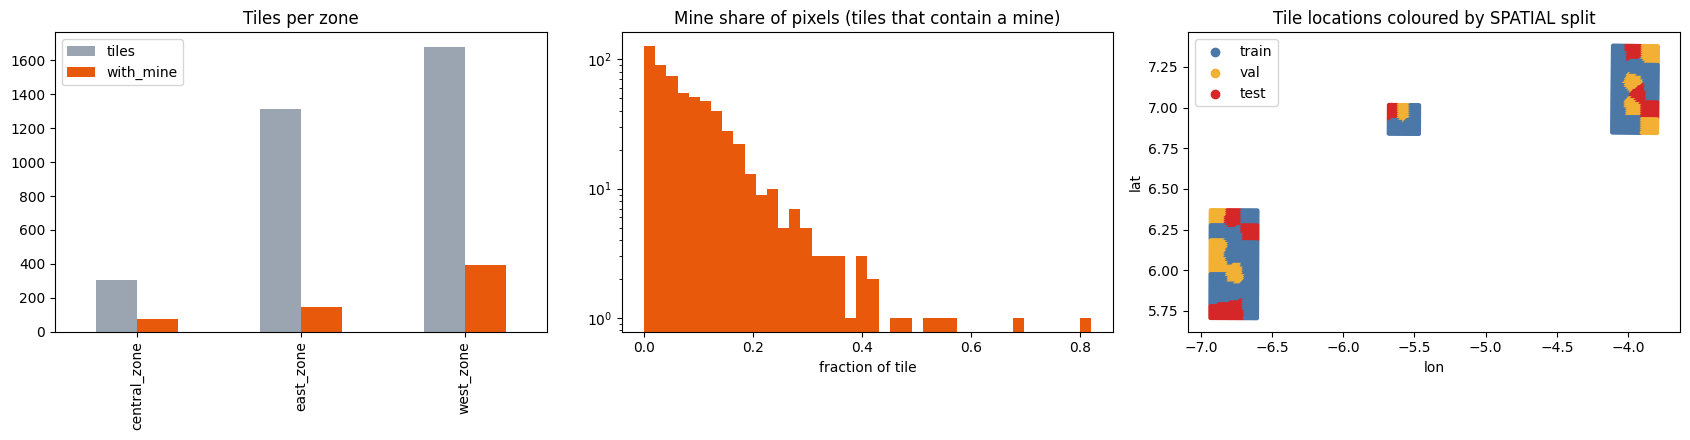

In [9]:
n_pos_tiles = int(tiles.has_positive.sum())
print(f"Tiles: {len(tiles):,} in {tiles.zone.nunique()} zones | tiles with a mine: {n_pos_tiles:,} ({n_pos_tiles/len(tiles):.1%})")
print(f"Mine pixels: {tiles.positive_pixels.sum():,} of {tiles.valid_pixels.sum():,} "
      f"= {tiles.positive_pixels.sum()/tiles.valid_pixels.sum():.3%}  ->  about {tiles.positive_pixels.sum()*PIXEL_HA:,.0f} ha of mines")
print("A model that predicts 'no mine' everywhere would score "
      f"{1 - tiles.positive_pixels.sum()/tiles.valid_pixels.sum():.2%} pixel accuracy -> we judge models by IoU / F1, not accuracy.")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
z = tiles.groupby("zone").agg(tiles=("tile_id", "count"), with_mine=("has_positive", "sum"))
z.plot(kind="bar", ax=ax[0], color=["#9aa5b1", "#e8590c"]); ax[0].set_title("Tiles per zone"); ax[0].set_xlabel("")
ax[1].hist(tiles.positive_fraction[tiles.has_positive == 1], bins=40, color="#e8590c")
ax[1].set_yscale("log"); ax[1].set_title("Mine share of pixels (tiles that contain a mine)"); ax[1].set_xlabel("fraction of tile")
colors = {"train": "#4c78a8", "val": "#f2b134", "test": "#d62728"}
ax[2].scatter(tiles.lon, tiles.lat, c=tiles.split_spatial.map(colors), s=6)
ax[2].set_title("Tile locations coloured by SPATIAL split"); ax[2].set_xlabel("lon"); ax[2].set_ylabel("lat")
for k, v in colors.items():
    ax[2].scatter([], [], c=v, label=k)
ax[2].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "dataset_overview.png", dpi=180); plt.show()

sampling pixels:   0%|          | 0/85 [00:00<?, ?it/s]

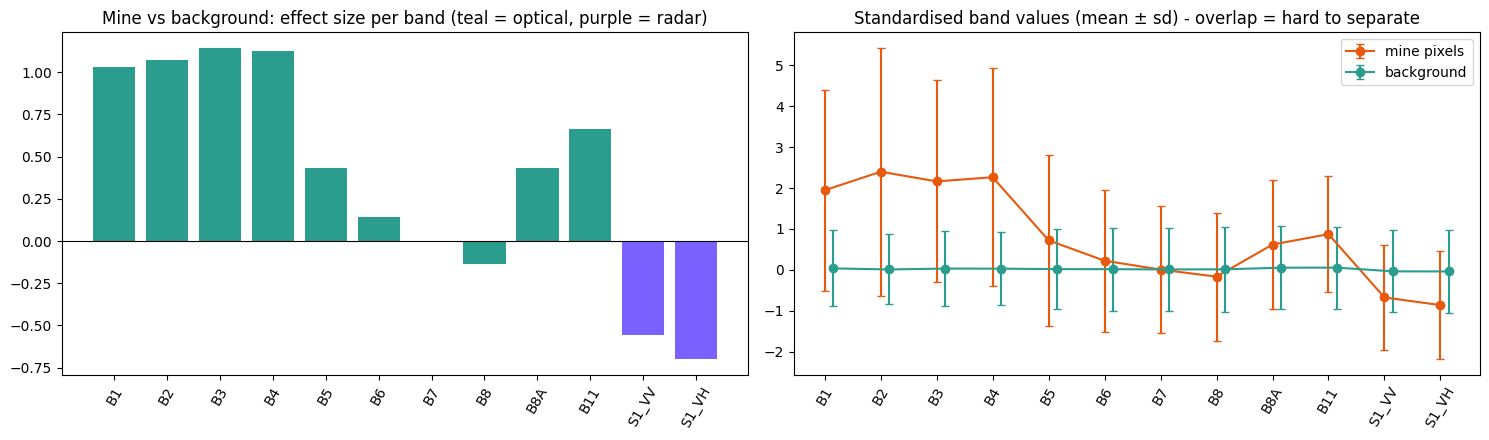

Write your interpretation from THIS figure (largest |d| bands separate best; check which are optical vs radar).


,band,cohen_d
2,B3,1.14
3,B4,1.13
1,B2,1.07
0,B1,1.03
11,S1_VH,-0.70
9,B11,0.66


In [10]:
# Which bands separate mine pixels from background? Effect size (Cohen's d) on standardised values.
rng = np.random.default_rng(SEED)
pos_vals, neg_vals = [], []
for r in tqdm(list(sample[sample.has_positive == 1].head(60).itertuples()) +
              list(sample[sample.has_positive == 0].head(30).itertuples()), desc="sampling pixels"):
    with rasterio.open(LOCAL_DIR / r.image_rel) as s:
        a = s.read(masked=True).filled(np.nan).astype(np.float32)
    with rasterio.open(LOCAL_DIR / r.mask_rel) as s:
        m = s.read(1, masked=True).filled(0)
    a = (a - band_mean[:, None, None].astype(np.float32)) / band_std[:, None, None].astype(np.float32)
    p, n = a[:, m == 1].T, a[:, m == 0].T
    pos_vals.append(p); neg_vals.append(n[rng.choice(len(n), min(400, len(n)), replace=False)] if len(n) else n)
P, N = np.concatenate(pos_vals), np.concatenate(neg_vals)
P, N = P[~np.isnan(P).any(1)], N[~np.isnan(N).any(1)]
pooled = np.sqrt((P.var(0) + N.var(0)) / 2)
cohen_d = (P.mean(0) - N.mean(0)) / np.maximum(pooled, 1e-6)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
cols = ["#2a9d8f" if i in OPTICAL_IDX else "#7b61ff" for i in range(12)]
ax[0].bar(BAND_NAMES, cohen_d, color=cols); ax[0].axhline(0, color="k", lw=.8)
ax[0].set_title("Mine vs background: effect size per band (teal = optical, purple = radar)")
ax[0].tick_params(axis="x", rotation=60)
ax[1].errorbar(range(12), P.mean(0), P.std(0), fmt="o-", color="#e8590c", capsize=3, label="mine pixels")
ax[1].errorbar(np.arange(12) + .15, N.mean(0), N.std(0), fmt="o-", color="#2a9d8f", capsize=3, label="background")
ax[1].set_xticks(range(12)); ax[1].set_xticklabels(BAND_NAMES, rotation=60)
ax[1].set_title("Standardised band values (mean ± sd) - overlap = hard to separate"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "band_separability.png", dpi=180); plt.show()
print("Write your interpretation from THIS figure (largest |d| bands separate best; check which are optical vs radar).")
display(pd.DataFrame({"band": BAND_NAMES, "cohen_d": cohen_d.round(2)}).sort_values("cohen_d", key=abs, ascending=False).head(6))

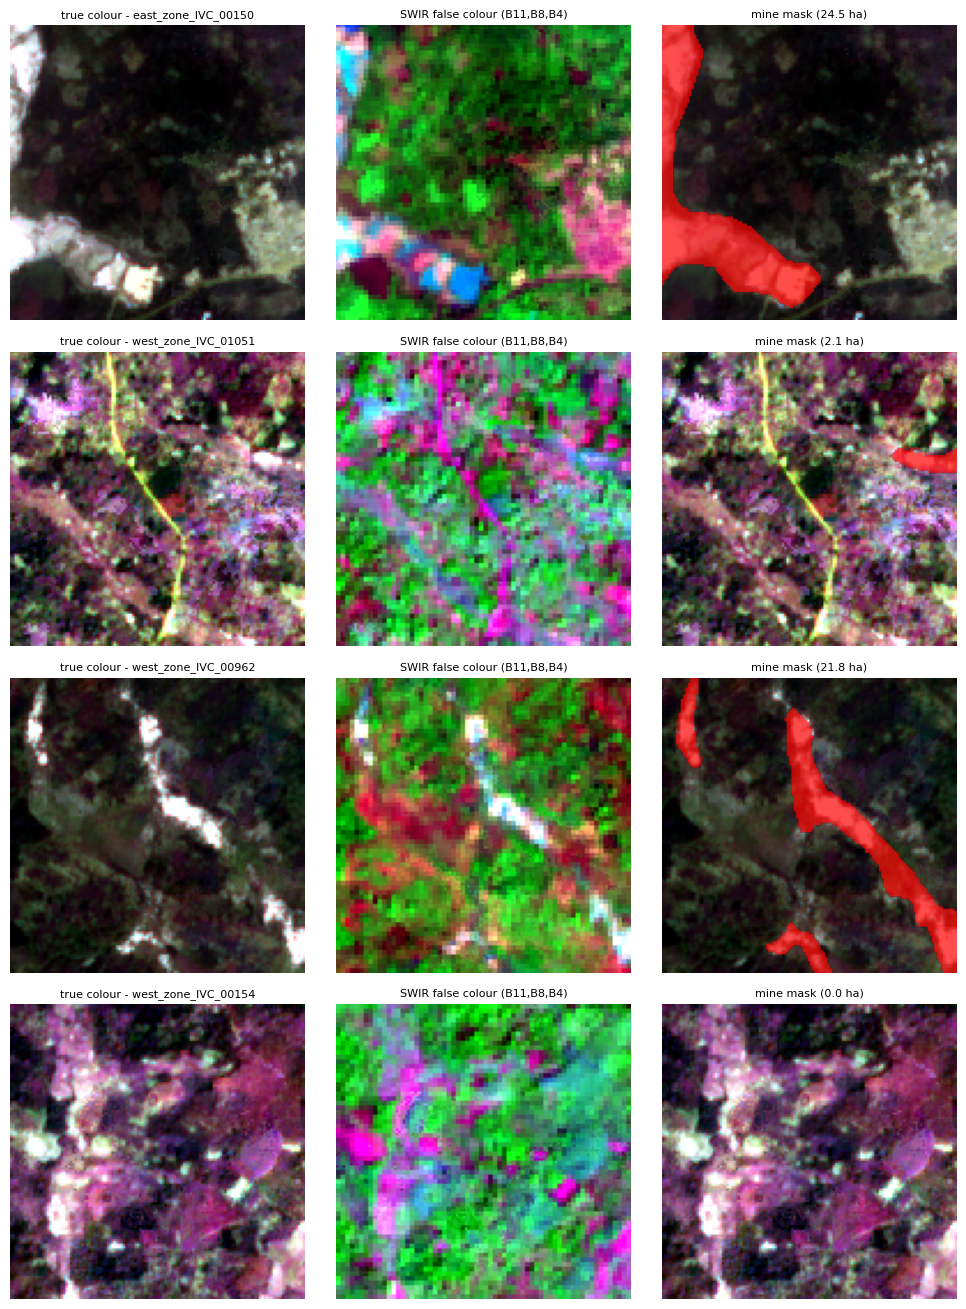

In [11]:
def stretch(a):
    lo, hi = np.nanpercentile(a, [2, 98])
    return np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)

def composite(img, idx):
    return np.dstack([stretch(img[i]) for i in idx])

picks = list(tiles[tiles.has_positive == 1].sample(3, random_state=SEED).itertuples()) + \
        list(tiles[tiles.has_positive == 0].sample(1, random_state=SEED).itertuples())
fig, ax = plt.subplots(len(picks), 3, figsize=(10, 3.3 * len(picks)))
for row, r in zip(ax, picks):
    with rasterio.open(LOCAL_DIR / r.image_rel) as s:
        img = s.read(masked=True).filled(np.nan).astype(np.float32)
    with rasterio.open(LOCAL_DIR / r.mask_rel) as s:
        m = s.read(1, masked=True).filled(0)
    row[0].imshow(composite(img, TRUE_COLOUR)); row[0].set_title(f"true colour - {r.tile_id}", fontsize=8)
    row[1].imshow(composite(img, SWIR_FALSE)); row[1].set_title("SWIR false colour (B11,B8,B4)", fontsize=8)
    row[2].imshow(composite(img, TRUE_COLOUR)); row[2].imshow(np.ma.masked_where(m != 1, m), cmap="autumn", alpha=.7)
    row[2].set_title(f"mine mask ({r.positive_pixels * PIXEL_HA:.1f} ha)", fontsize=8)
    for a in row: a.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "sample_tiles.png", dpi=180); plt.show()

## 7. Save the data tables

In [12]:
tiles.to_csv(OUT_DIR / "tiles.csv", index=False)
json.dump({"mean": band_mean.tolist(), "std": band_std.tolist(), "seed": SEED,
           "sample_tiles": int(len(sample))}, open(OUT_DIR / "norm_stats.json", "w"), indent=2)
json.dump({"band_names": BAND_NAMES, "source": source, "optical_idx": OPTICAL_IDX,
           "radar_idx": RADAR_IDX, "true_colour": TRUE_COLOUR, "swir_false": SWIR_FALSE},
          open(OUT_DIR / "band_names.json", "w"), indent=2)
print("Saved tiles.csv, norm_stats.json, band_names.json and figures to", OUT_DIR)
print("Next: section 8 (models) below.")

Saved tiles.csv, norm_stats.json, band_names.json and figures to /content/drive/MyDrive/mining-asm-ivc/outputs
Next: section 8 (models) below.


## 8. Models - shared code and settings
The next cell writes `mineseg.py` (dataset, U-Net, losses, training loop, threshold tuning, metrics) next to this notebook, so **every model is trained and scored by exactly the same code.** Then set `QUICK_TEST` and run the setup cell.

In [13]:
%%writefile mineseg.py
"""mineseg.py - shared code for the artisanal-mine segmentation project.

Used by 02_train_eval.ipynb. Everything that must be identical across models
(data loading, seeding, training loop, threshold tuning, metrics) lives here so
that every model is trained and scored under exactly the same rules.
"""
from __future__ import annotations

import json
import random
import time
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader, Dataset

SEED = 4050
PIXEL_HA = 0.01            # one 10 m x 10 m Sentinel pixel = 0.01 hectare
TILE_MIN_PIXELS = 10       # a tile counts as "mine detected" if >= this many predicted pixels
THR_GRID = np.linspace(0.05, 0.95, 19)


# --------------------------------------------------------------------------- #
# Reproducibility
# --------------------------------------------------------------------------- #
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def make_loader(ds: Dataset, batch_size: int, shuffle: bool, drop_last: bool = False) -> DataLoader:
    """Single-process loader (data is preloaded in RAM) with a seeded shuffle order."""
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last,
                      num_workers=0, generator=g, pin_memory=torch.cuda.is_available())


# --------------------------------------------------------------------------- #
# Data
# --------------------------------------------------------------------------- #
class TileDataset(Dataset):
    """Sentinel tiles preloaded as normalised float16 arrays.

    frame : rows with image_path and mask_path
    bands : 0-based band indices to keep (None = all). Used for the optical-only ablation.
    Missing (nodata) input pixels are set to the band mean, i.e. 0 after normalisation.
    """

    def __init__(self, frame: pd.DataFrame, mean, std, bands=None, augment: bool = False):
        import rasterio  # imported here so the dashboard/other code never needs it

        self.frame = frame.reset_index(drop=True)
        n_all = len(mean)
        self.bands = list(range(n_all)) if bands is None else list(bands)
        m = np.asarray(mean, np.float32)[self.bands, None, None]
        s = np.maximum(np.asarray(std, np.float32)[self.bands, None, None], 1e-6)
        self.mean, self.std = m, s
        self.augment = augment

        xs, ys = [], []
        for row in self.frame.itertuples():
            with rasterio.open(row.image_path) as src:
                ma = src.read([b + 1 for b in self.bands], masked=True)
            invalid = np.ma.getmaskarray(ma)
            img = np.where(invalid, m, ma.filled(0).astype(np.float32))
            img = np.nan_to_num((img - m) / s)
            with rasterio.open(row.mask_path) as src:
                mk = src.read(1, masked=True).filled(0)
            xs.append(img.astype(np.float16))
            ys.append((mk == 1).astype(np.uint8))
        self.X = np.stack(xs)          # (N, C, H, W)
        self.Y = np.stack(ys)          # (N, H, W)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x = self.X[i].astype(np.float32)
        y = self.Y[i].astype(np.float32)
        if self.augment:  # synchronised flips / 90-degree rotations keep image and mask aligned
            if random.random() < 0.5:
                x, y = x[:, :, ::-1], y[:, ::-1]
            if random.random() < 0.5:
                x, y = x[:, ::-1, :], y[::-1, :]
            k = random.randint(0, 3)
            if k:
                x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k, axes=(0, 1))
        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.from_numpy(np.ascontiguousarray(y[None])))

    def select_bands(self, bands, augment=None) -> "TileDataset":
        """Cheap view with only some bands (indices relative to the current bands), e.g. optical-only."""
        import copy
        new = copy.copy(self)
        new.X = self.X[:, list(bands)]
        new.mean, new.std = self.mean[list(bands)], self.std[list(bands)]
        new.bands = [self.bands[b] for b in bands]
        if augment is not None:
            new.augment = augment
        return new

    def denormalise(self, i) -> np.ndarray:
        """Back to the original value scale, shape (C, H, W)."""
        return self.X[i].astype(np.float32) * self.std + self.mean


# --------------------------------------------------------------------------- #
# Models
# --------------------------------------------------------------------------- #
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.net(x)


class Down(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.pool, self.conv = nn.MaxPool2d(2), DoubleConv(cin, cout)

    def forward(self, x):
        return self.conv(self.pool(x))


class Up(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.up = nn.ConvTranspose2d(cin, cin // 2, 2, stride=2)
        self.conv = DoubleConv(cin, cout)

    def forward(self, x, skip):
        x = self.up(x)
        dy, dx = skip.size(2) - x.size(2), skip.size(3) - x.size(3)
        if dy or dx:
            x = F.pad(x, [dx // 2, dx - dx // 2, dy // 2, dy - dy // 2])
        return self.conv(torch.cat([skip, x], dim=1))


class UNet(nn.Module):
    """Plain U-Net trained from scratch. in_ch is 12 (optical + radar) or 10 (optical only)."""

    def __init__(self, in_ch=12, out_ch=1, base=16):
        super().__init__()
        b = base
        self.inc = DoubleConv(in_ch, b)
        self.d1, self.d2, self.d3, self.d4 = Down(b, 2 * b), Down(2 * b, 4 * b), Down(4 * b, 8 * b), Down(8 * b, 16 * b)
        self.u1, self.u2, self.u3, self.u4 = Up(16 * b, 8 * b), Up(8 * b, 4 * b), Up(4 * b, 2 * b), Up(2 * b, b)
        self.out = nn.Conv2d(b, out_ch, 1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.d1(x1)
        x3 = self.d2(x2)
        x4 = self.d3(x3)
        x5 = self.d4(x4)
        x = self.u1(x5, x4)
        x = self.u2(x, x3)
        x = self.u3(x, x2)
        x = self.u4(x, x1)
        return self.out(x)


def build_model(arch: str, in_ch: int, pretrained: bool = False) -> nn.Module:
    """arch: 'unet' or 'deeplab'.

    DeepLabV3+ comes from segmentation_models_pytorch, which adapts the first conv to any number
    of input channels correctly. Output stride 8 and small atrous rates are used because our tiles are
    only 128 px: the library defaults (rates 12/24/36) are meant for ~512 px inputs and would
    collapse to 1x1 convolutions on such a small feature map.
    """
    if arch == "unet":
        return UNet(in_ch=in_ch)
    if arch == "deeplab":
        import segmentation_models_pytorch as smp
        return smp.DeepLabV3Plus(
            encoder_name="resnet34",
            encoder_weights="imagenet" if pretrained else None,
            in_channels=in_ch, classes=1,
            encoder_output_stride=8, decoder_atrous_rates=(3, 6, 9))
    raise ValueError(arch)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


# --------------------------------------------------------------------------- #
# Losses
# --------------------------------------------------------------------------- #
def capped_pos_weight(positive_pixels: int, valid_pixels: int, cap: float = 20.0) -> float:
    """neg/pos ratio, capped. An uncapped ratio (~100 for 1% positives) makes models over-predict mines."""
    neg = valid_pixels - positive_pixels
    return float(min(neg / max(positive_pixels, 1), cap))


class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        p = torch.sigmoid(logits).flatten(1)
        t = targets.flatten(1)
        inter = (p * t).sum(1)
        return (1 - (2 * inter + self.smooth) / (p.sum(1) + t.sum(1) + self.smooth)).mean()


class HybridLoss(nn.Module):
    """(1 - w) * weighted BCE + w * Dice."""

    def __init__(self, pos_weight: float, dice_weight: float = 0.5):
        super().__init__()
        self.register_buffer("pw", torch.tensor([pos_weight]))
        self.w, self.dice = dice_weight, DiceLoss()

    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets, pos_weight=self.pw)
        return (1 - self.w) * bce + self.w * self.dice(logits, targets)


# --------------------------------------------------------------------------- #
# Training
# --------------------------------------------------------------------------- #
@torch.no_grad()
def _val_pass(model, loader, loss_fn, device):
    model.eval()
    thr = torch.tensor(THR_GRID, dtype=torch.float32, device=device)[:, None]
    tp = torch.zeros(len(THR_GRID), device=device)
    fp, fn = torch.zeros_like(tp), torch.zeros_like(tp)
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * x.size(0)
        n += x.size(0)
        p, t = torch.sigmoid(logits).flatten()[None], y.flatten()[None] > 0.5
        pred = p >= thr
        tp += (pred & t).sum(1)
        fp += (pred & ~t).sum(1)
        fn += (~pred & t).sum(1)
    iou = (tp / (tp + fp + fn).clamp(min=1)).cpu().numpy()
    return total_loss / n, float(iou.max()), float(THR_GRID[iou.argmax()])


def train_model(model, train_ds, val_ds, loss_fn, device, epochs=30, lr=3e-4, batch_size=16,
                patience=6, weight_path: Path | None = None, verbose=True):
    """Train with AdamW, checkpoint and early-stop on validation IoU (best threshold on a grid).

    Returns (model with best weights loaded, history DataFrame, training seconds).
    """
    model.to(device)
    loss_fn.to(device)
    train_loader = make_loader(train_ds, batch_size, shuffle=True, drop_last=True)  # avoids 1-sample BatchNorm batches
    val_loader = make_loader(val_ds, batch_size, shuffle=False)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)

    best_iou, best_state, bad, hist = -1.0, None, 0, []
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        run = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(x), y)
            loss.backward()
            opt.step()
            run += loss.item() * x.size(0)
        train_loss = run / (len(train_loader) * train_loader.batch_size)
        val_loss, val_iou, val_thr = _val_pass(model, val_loader, loss_fn, device)
        sched.step(val_iou)
        hist.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss, val_iou=val_iou,
                         val_thr=val_thr, lr=opt.param_groups[0]["lr"]))
        if verbose:
            print(f"epoch {epoch:02d} | train {train_loss:.4f} | val {val_loss:.4f} | "
                  f"val IoU {val_iou:.4f} @ thr {val_thr:.2f}")
        if val_iou > best_iou:
            best_iou, best_state, bad = val_iou, deepcopy(model.state_dict()), 0
            if weight_path is not None:
                torch.save(best_state, weight_path)
        else:
            bad += 1
            if bad >= patience:
                if verbose:
                    print("early stopping")
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), time.time() - t0


# --------------------------------------------------------------------------- #
# Prediction and evaluation
# --------------------------------------------------------------------------- #
@torch.no_grad()
def predict_probs(model, ds: Dataset, device, batch_size=32) -> np.ndarray:
    model.eval().to(device)
    out = []
    for x, _ in make_loader(ds, batch_size, shuffle=False):
        out.append(torch.sigmoid(model(x.to(device)))[:, 0].cpu().numpy().astype(np.float16))
    return np.concatenate(out)


def best_threshold(probs: np.ndarray, truth: np.ndarray, bins: int = 1000) -> float:
    """Threshold maximising F1 (equivalently IoU) on the given pixels. Use VALIDATION data only."""
    p = probs.ravel().astype(np.float32)
    t = truth.ravel().astype(bool)
    pos, _ = np.histogram(p[t], bins=bins, range=(0, 1))
    neg, _ = np.histogram(p[~t], bins=bins, range=(0, 1))
    tp = pos[::-1].cumsum()[::-1].astype(np.float64)    # pixels with prob >= bin lower edge
    fp = neg[::-1].cumsum()[::-1].astype(np.float64)
    fn = t.sum() - tp
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    return float(np.argmax(f1) / bins)


def seg_metrics(probs: np.ndarray, truth: np.ndarray, thr: float) -> dict:
    pred = probs.astype(np.float32) >= thr
    t = truth.astype(bool)
    tp, fp = int((pred & t).sum()), int((pred & ~t).sum())
    fn, tn = int((~pred & t).sum()), int((~pred & ~t).sum())
    n = len(t)
    tile_true = t.reshape(n, -1).any(1)
    tile_pred = pred.reshape(n, -1).sum(1) >= TILE_MIN_PIXELS
    return dict(
        threshold=float(thr),
        iou=tp / max(tp + fp + fn, 1),
        f1=2 * tp / max(2 * tp + fp + fn, 1),
        precision=tp / max(tp + fp, 1),
        recall=tp / max(tp + fn, 1),
        pixel_accuracy=(tp + tn) / max(tp + fp + fn + tn, 1),
        tile_accuracy=float((tile_true == tile_pred).mean()),
        tile_f1=float(f1_score(tile_true, tile_pred, zero_division=0)),
        tp=tp, fp=fp, fn=fn, tn=tn,
        baseline_pixel_accuracy=float(1 - t.mean()),   # accuracy of "predict no mine everywhere"
    )


def evaluate_probs(name, val_probs, val_truth, test_probs, test_truth, **extra) -> dict:
    """Threshold from validation, scores on test (test is looked at exactly once, here)."""
    thr = best_threshold(val_probs, val_truth)
    row = dict(model=name, **seg_metrics(test_probs, test_truth, thr), **extra)
    return row


def time_inference(model, ds, device, n=64) -> float:
    """Milliseconds per tile."""
    sub = torch.stack([ds[i][0] for i in range(min(n, len(ds)))]).to(device)
    model.eval()
    with torch.no_grad():
        model(sub[:2])
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        model(sub)
        if device.type == "cuda":
            torch.cuda.synchronize()
    return 1000 * (time.time() - t0) / len(sub)


def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)


Writing mineseg.py


In [14]:
import sys, json, time, shutil, importlib.util, subprocess
from pathlib import Path
for pkg, pipname in [("rasterio", "rasterio"), ("xgboost", "xgboost>=2.0"),
                     ("segmentation_models_pytorch", "segmentation-models-pytorch")]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pipname], check=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn
from IPython.display import display

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/mining-asm-ivc")
    LOCAL_DIR = Path("/content/mining-data")
    sys.path.insert(0, str(PROJECT_DIR))            # put mineseg.py here (or next to this notebook)
except ImportError:
    PROJECT_DIR, LOCAL_DIR = Path("./project"), Path("./mining-data")
sys.path.insert(0, "."); sys.path.insert(0, "/content")
import mineseg as ms

OUT_DIR = PROJECT_DIR / "outputs"
QUICK_TEST = False   # True = 2-epoch smoke test on ~450 tiles; results go to outputs/quick_test
RUN_DIR = OUT_DIR / "quick_test" if QUICK_TEST else OUT_DIR
W_DIR, P_DIR, R_DIR, FIG_DIR, BUNDLE_DIR = (RUN_DIR / n for n in ("weights", "preds", "results", "figures", "dashboard_data"))
for d in (W_DIR, P_DIR, R_DIR, FIG_DIR, BUNDLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "(CPU: training will be slow)")

# ---- settings ----
EPOCHS, BATCH, PATIENCE = (2, 16, 2) if QUICK_TEST else (30, 16, 6)
MAIN_SPLIT = "split_random"          # the main comparison; the best model is re-checked on split_spatial at the end

tiles = pd.read_csv(OUT_DIR / "tiles.csv")
if QUICK_TEST:
    tiles = pd.concat([g.sample(min(len(g), 150), random_state=ms.SEED) for _, g in tiles.groupby("split_random")])
    tiles = tiles.reset_index(drop=True)
tiles["image_path"] = tiles.image_rel.map(lambda r: str(LOCAL_DIR / r))
tiles["mask_path"] = tiles.mask_rel.map(lambda r: str(LOCAL_DIR / r))
assert Path(tiles.image_path[0]).exists(), "TIFFs not found - re-run notebook 1 (it re-extracts them)."
ns = json.load(open(OUT_DIR / "norm_stats.json")); bn = json.load(open(OUT_DIR / "band_names.json"))
MEAN, STD, BAND_NAMES, OPT_IDX = np.array(ns["mean"]), np.array(ns["std"]), bn["band_names"], bn["optical_idx"]
ms.set_seed()
print(tiles[MAIN_SPLIT].value_counts().to_dict(), "| bands:", BAND_NAMES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda Tesla T4
{'train': 1981, 'test': 661, 'val': 660} | bands: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'S1_VV', 'S1_VH']


## 9. Load the data into RAM
Tiles are small, so the whole split is preloaded (about 1 GB per 1,000 tiles); this makes every epoch fast. If Colab runs out of memory, switch to a High-RAM runtime.

In [15]:
def load_split(split_col):
    parts = {s: tiles[tiles[split_col] == s] for s in ("train", "val", "test")}
    return (ms.TileDataset(parts["train"], MEAN, STD, augment=True),
            ms.TileDataset(parts["val"], MEAN, STD),
            ms.TileDataset(parts["test"], MEAN, STD))

DATA = {MAIN_SPLIT: load_split(MAIN_SPLIT)}
tr, va, te = DATA[MAIN_SPLIT]
for name, d in zip(("train", "val", "test"), (tr, va, te)):
    assert np.isfinite(d.X.astype(np.float32)).all()
    print(f"{name:5s} tiles={len(d):5d}  X{d.X.shape}  mine pixels={d.Y.mean():.3%}")
pos_weight = ms.capped_pos_weight(int(tr.Y.sum()), tr.Y.size)
print(f"pos_weight (capped at 20): {pos_weight:.1f}")

train tiles= 1981  X(1981, 12, 128, 128)  mine pixels=1.800%
val   tiles=  660  X(660, 12, 128, 128)  mine pixels=1.676%
test  tiles=  661  X(661, 12, 128, 128)  mine pixels=1.457%
pos_weight (capped at 20): 20.0


## 10. Classical baseline: XGBoost on single pixels
Trains on all mine pixels (capped) plus 5x as many random background pixels from training tiles, then predicts every pixel of the validation and test tiles. Scored with exactly the same threshold-on-validation procedure as the neural networks.

In [16]:
from xgboost import XGBClassifier

def sample_pixels(ds, max_pos=300_000, neg_per_pos=5, seed=ms.SEED):
    rng = np.random.default_rng(seed)
    N, C, H, W = ds.X.shape
    flat = ds.Y.reshape(-1)
    pos = np.flatnonzero(flat == 1)
    pos = rng.choice(pos, min(len(pos), max_pos), replace=False)
    neg = rng.choice(np.flatnonzero(flat == 0), min(int((flat == 0).sum()), len(pos) * neg_per_pos), replace=False)
    idx = np.concatenate([pos, neg])
    t, p = idx // (H * W), idx % (H * W)
    return ds.X[t, :, p // W, p % W].astype(np.float32), flat[idx]

def xgb_predict(clf, ds, chunk=50):
    out = []
    for i in range(0, len(ds), chunk):
        x = ds.X[i:i + chunk].astype(np.float32); n, c, h, w = x.shape
        out.append(clf.predict_proba(x.transpose(0, 2, 3, 1).reshape(-1, c))[:, 1].reshape(n, h, w).astype(np.float16))
    return np.concatenate(out)

def save_run(tag, name, row, test_probs, test_ds, history=None):
    np.savez_compressed(P_DIR / f"{tag}.npz", test=test_probs, tile_id=test_ds.frame.tile_id.to_numpy(), threshold=row["threshold"])
    if history is not None:
        history.to_csv(R_DIR / f"{tag}_history.csv", index=False)
    ms.save_json(row, R_DIR / f"{tag}.json")

tag = f"{MAIN_SPLIT}__xgboost"
if (R_DIR / f"{tag}.json").exists():
    print("xgboost already done:", json.load(open(R_DIR / f"{tag}.json"))["iou"])
else:
    ms.set_seed()
    Xp, yp = sample_pixels(tr)
    print("training pixels:", Xp.shape, f"| mine share {yp.mean():.1%}")
    clf = XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                        tree_method="hist", device="cuda" if device.type == "cuda" else "cpu",
                        eval_metric="aucpr", random_state=ms.SEED, n_jobs=-1)
    t0 = time.time(); clf.fit(Xp, yp); secs = time.time() - t0
    vp, tp_ = xgb_predict(clf, va), xgb_predict(clf, te)
    row = ms.evaluate_probs("xgboost", vp, va.Y, tp_, te.Y, split=MAIN_SPLIT, train_seconds=secs,
                            params=int(clf.n_estimators * 2 ** clf.max_depth),  # leaf-count upper bound, not comparable to NN parameters
                            ms_per_tile=np.nan, epochs_run=clf.n_estimators)
    save_run(tag, "xgboost", row, tp_, te)
    print({k: round(v, 4) for k, v in row.items() if k in ("iou", "f1", "precision", "recall", "tile_f1")})

xgboost already done: 0.4196191830303962


## 11. Deep learning runs (same loop for every model)

In [17]:
class WeightedBCE(nn.Module):
    def __init__(self, pw):
        super().__init__(); self.register_buffer("pw", torch.tensor([pw]))
    def forward(self, logits, y):
        return nn.functional.binary_cross_entropy_with_logits(logits, y, pos_weight=self.pw)

EXPERIMENTS = {
    "unet_bce":         dict(arch="unet",    bands="all",     loss="bce",    pretrained=False),
    "unet_hybrid":      dict(arch="unet",    bands="all",     loss="hybrid", pretrained=False),
    "unet_optical":     dict(arch="unet",    bands="optical", loss="hybrid", pretrained=False),
    "deeplab_random":   dict(arch="deeplab", bands="all",     loss="hybrid", pretrained=False),
    "deeplab_imagenet": dict(arch="deeplab", bands="all",     loss="hybrid", pretrained=True),
}

def run_experiment(name, cfg, split_col):
    tag = f"{split_col}__{name}"
    if (R_DIR / f"{tag}.json").exists():
        print(f"[skip] {tag} already finished"); return json.load(open(R_DIR / f"{tag}.json"))
    if split_col not in DATA:
        DATA[split_col] = load_split(split_col)
    tr_, va_, te_ = DATA[split_col]
    if cfg["bands"] == "optical":
        tr_, va_, te_ = (d.select_bands(OPT_IDX) for d in (tr_, va_, te_))
    ms.set_seed()
    model = ms.build_model(cfg["arch"], in_ch=tr_.X.shape[1], pretrained=cfg["pretrained"])
    pw = ms.capped_pos_weight(int(tr_.Y.sum()), tr_.Y.size)
    loss_fn = WeightedBCE(pw) if cfg["loss"] == "bce" else ms.HybridLoss(pw, dice_weight=0.5)
    print(f"\n=== {tag} | params {ms.count_params(model):,} ===")
    model, hist, secs = ms.train_model(model, tr_, va_, loss_fn, device, epochs=EPOCHS, batch_size=BATCH,
                                       patience=PATIENCE, weight_path=W_DIR / f"{tag}.pt")
    vp, tp_ = ms.predict_probs(model, va_, device), ms.predict_probs(model, te_, device)
    row = ms.evaluate_probs(name, vp, va_.Y, tp_, te_.Y, split=split_col, train_seconds=secs,
                            params=ms.count_params(model), ms_per_tile=ms.time_inference(model, te_, device),
                            epochs_run=len(hist))
    save_run(tag, name, row, tp_, te_, hist)
    print({k: round(v, 4) for k, v in row.items() if k in ("iou", "f1", "precision", "recall", "tile_f1")})
    del model; torch.cuda.empty_cache()
    return row

for name, cfg in EXPERIMENTS.items():
    run_experiment(name, cfg, MAIN_SPLIT)

[skip] split_random__unet_bce already finished
[skip] split_random__unet_hybrid already finished
[skip] split_random__unet_optical already finished
[skip] split_random__deeplab_random already finished
[skip] split_random__deeplab_imagenet already finished


## 12. Results: leaderboard, why accuracy is misleading, learning curves

,model,iou,f1,precision,recall,tile_f1,tile_accuracy,pixel_accuracy,baseline_pixel_accuracy,threshold,params,train_seconds,ms_per_tile,epochs_run
0,unet_hybrid,0.5630,0.7204,0.6992,0.7430,0.8074,0.9213,0.9916,0.9854,0.933,1945345,283.3998,0.7651,28
1,unet_optical,0.5601,0.7180,0.7090,0.7273,0.8000,0.9168,0.9917,0.9854,0.921,1945057,229.6593,0.6336,24
2,unet_bce,0.5593,0.7174,0.6956,0.7406,0.8195,0.9274,0.9915,0.9854,0.914,1945345,285.4205,0.6573,29
3,deeplab_imagenet,0.5102,0.6756,0.6393,0.7163,0.7291,0.8775,0.9900,0.9854,0.875,22465681,474.6209,3.1276,17
4,deeplab_random,0.5094,0.6750,0.6344,0.7211,0.7509,0.8896,0.9899,0.9854,0.895,22465681,393.1014,3.1812,14
5,xgboost,0.4196,0.5912,0.6339,0.5538,0.4621,0.5809,0.9888,0.9854,0.820,76800,7.6706,NaN,300


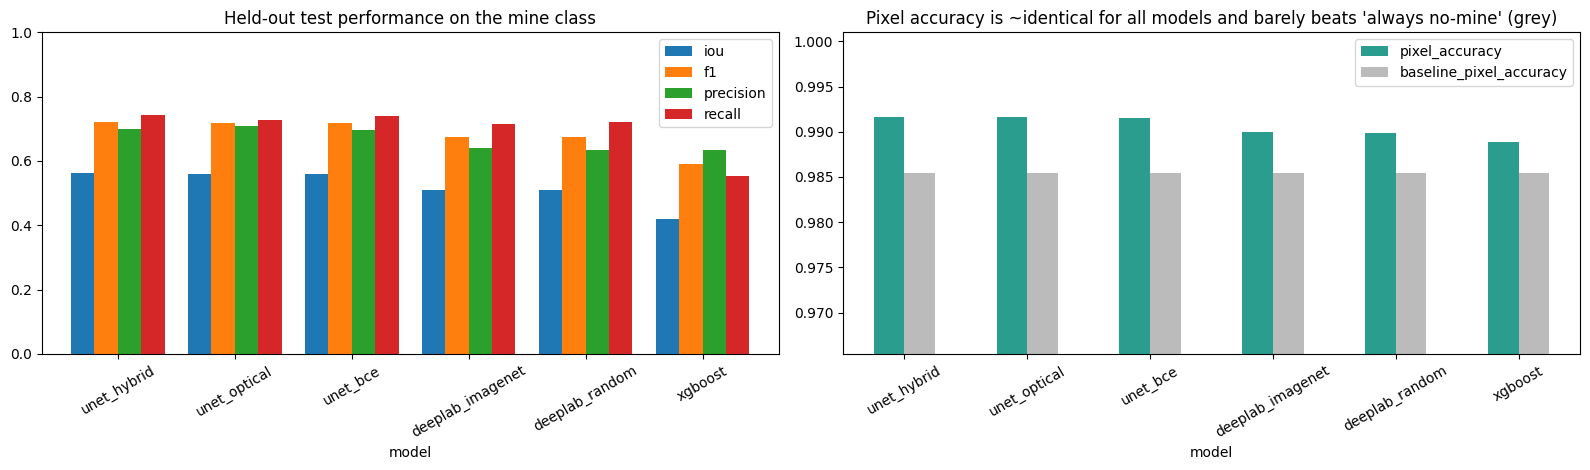

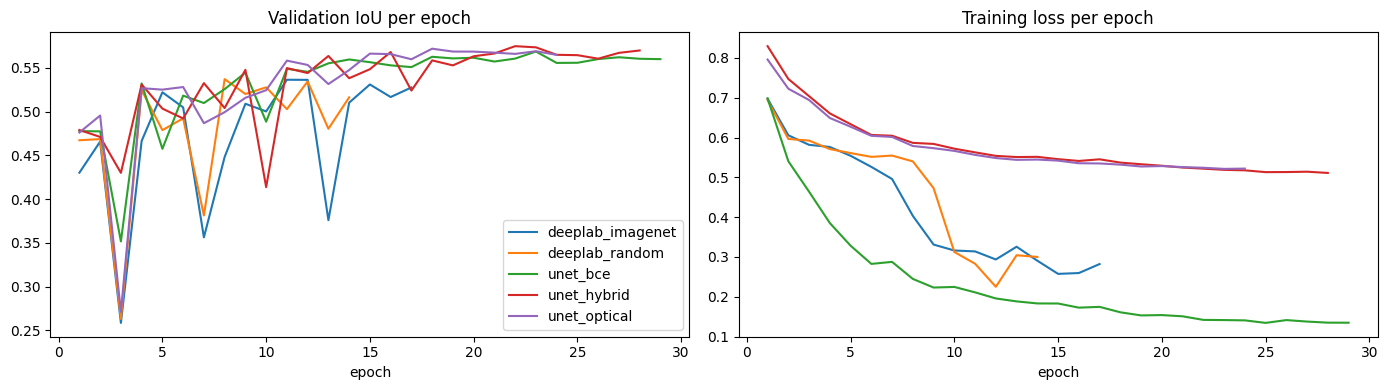

In [18]:
def load_results(split_col):
    rows = [json.load(open(p)) for p in sorted(R_DIR.glob(f"{split_col}__*.json"))]
    return pd.DataFrame(rows).sort_values("iou", ascending=False).reset_index(drop=True)

lb = load_results(MAIN_SPLIT)
show = ["model", "iou", "f1", "precision", "recall", "tile_f1", "tile_accuracy", "pixel_accuracy",
        "baseline_pixel_accuracy", "threshold", "params", "train_seconds", "ms_per_tile", "epochs_run"]
display(lb[show].round(4))
lb.to_csv(RUN_DIR / "leaderboard.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
lb.set_index("model")[["iou", "f1", "precision", "recall"]].plot(kind="bar", ax=ax[0], width=.8)
ax[0].set_title("Held-out test performance on the mine class"); ax[0].set_ylim(0, 1); ax[0].tick_params(axis="x", rotation=30)
lb.set_index("model")[["pixel_accuracy", "baseline_pixel_accuracy"]].plot(kind="bar", ax=ax[1], color=["#2a9d8f", "#bbb"])
ax[1].set_ylim(lb.baseline_pixel_accuracy.min() - .02, 1.001); ax[1].tick_params(axis="x", rotation=30)
ax[1].set_title("Pixel accuracy is ~identical for all models and barely beats 'always no-mine' (grey)")
plt.tight_layout(); plt.savefig(FIG_DIR / "leaderboard.png", dpi=180); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for p in sorted(R_DIR.glob(f"{MAIN_SPLIT}__*_history.csv")):
    h = pd.read_csv(p); label = p.stem.replace(f"{MAIN_SPLIT}__", "").replace("_history", "")
    ax[0].plot(h.epoch, h.val_iou, label=label); ax[1].plot(h.epoch, h.train_loss, label=label)
ax[0].set_title("Validation IoU per epoch"); ax[1].set_title("Training loss per epoch"); ax[0].legend(); ax[0].set_xlabel("epoch"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(FIG_DIR / "learning_curves.png", dpi=180); plt.show()

## 13. Where does the best model fail?
Green = correct mine pixels, red = false alarms, blue = missed mine. Use these in the discussion section.

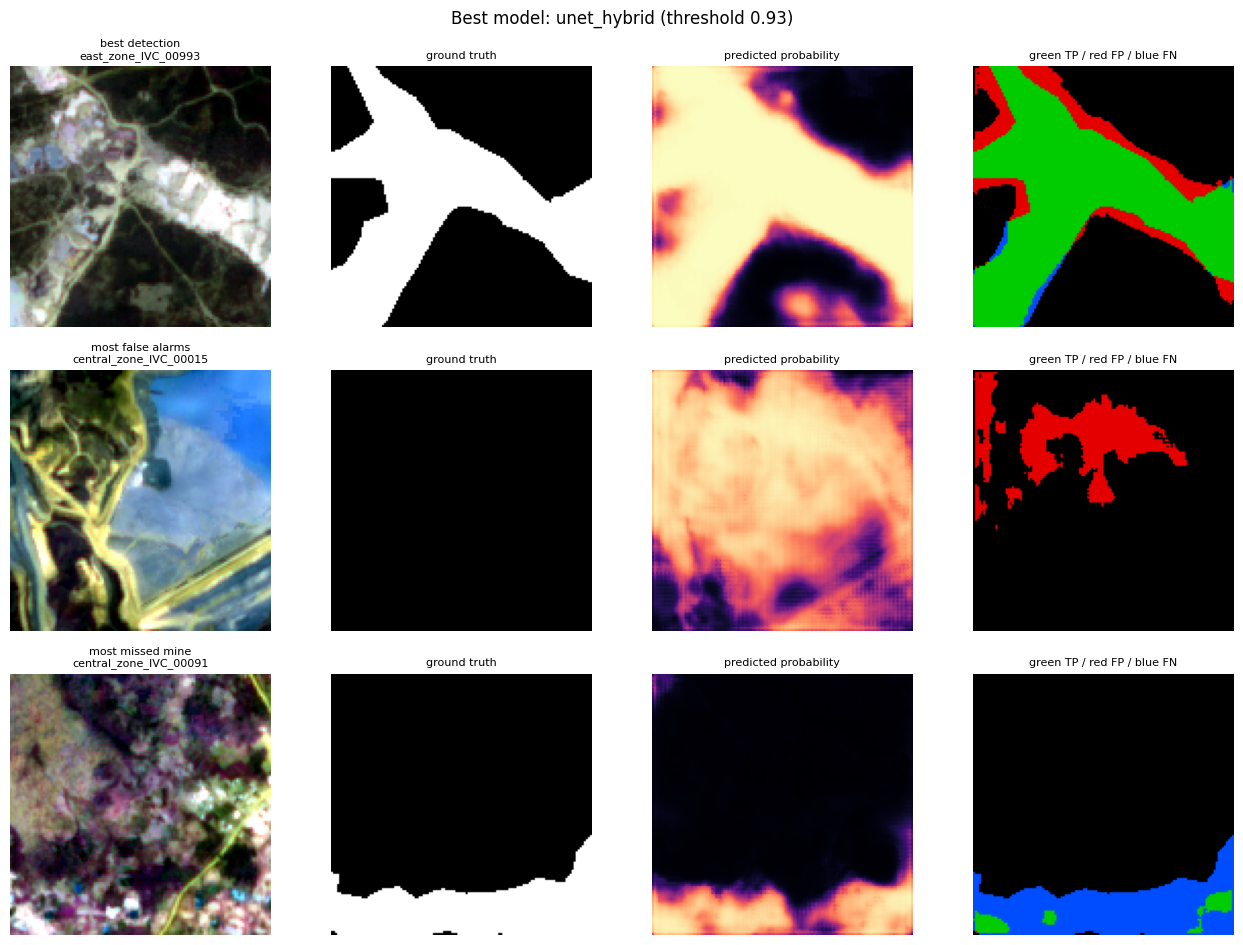

In [19]:
best = lb.model[0] if lb.model[0] != "xgboost" else lb.model[lb.model != "xgboost"].iloc[0]
z = np.load(P_DIR / f"{MAIN_SPLIT}__{best}.npz", allow_pickle=True)
probs, thr = z["test"].astype(np.float32), float(z["threshold"])
pred, truth = probs >= thr, te.Y.astype(bool)
tp_n, fp_n, fn_n = ((pred & truth).sum((1, 2)), (pred & ~truth).sum((1, 2)), (~pred & truth).sum((1, 2)))
order = {"best detection": int(np.argmax(tp_n)), "most false alarms": int(np.argmax(fp_n)), "most missed mine": int(np.argmax(fn_n))}
rgb_idx = bn["true_colour"]

def stretch(a):
    lo, hi = np.percentile(a, [2, 98]); return np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)

fig, ax = plt.subplots(len(order), 4, figsize=(13, 3.2 * len(order)))
for row, (title, i) in zip(ax, order.items()):
    img = te.denormalise(i)
    rgb = np.dstack([stretch(img[b]) for b in rgb_idx])
    err = np.zeros((*pred[i].shape, 3)); err[pred[i] & truth[i]] = (0, .8, 0); err[pred[i] & ~truth[i]] = (.9, 0, 0); err[~pred[i] & truth[i]] = (0, .3, 1)
    row[0].imshow(rgb); row[0].set_title(f"{title}\n{te.frame.tile_id[i]}", fontsize=8)
    row[1].imshow(truth[i], cmap="gray"); row[1].set_title("ground truth", fontsize=8)
    row[2].imshow(probs[i], vmin=0, vmax=1, cmap="magma"); row[2].set_title("predicted probability", fontsize=8)
    row[3].imshow(err); row[3].set_title("green TP / red FP / blue FN", fontsize=8)
    for a in row: a.axis("off")
plt.suptitle(f"Best model: {best} (threshold {thr:.2f})"); plt.tight_layout()
plt.savefig(FIG_DIR / "error_analysis.png", dpi=180); plt.show()

## 14. Honest generalisation check: spatial split
Re-train the best model with whole geographic blocks held out. A big drop from the random-split score means the random split was optimistic (neighbouring tiles look alike).

In [20]:
cfg = EXPERIMENTS[best]
row_sp = run_experiment(best, cfg, "split_spatial")
cmp_df = pd.DataFrame([json.load(open(R_DIR / f"{MAIN_SPLIT}__{best}.json")), row_sp])
cmp_df["split"] = ["random (neighbours can leak)", "spatial (blocks held out)"]
display(cmp_df[["model", "split", "iou", "f1", "precision", "recall", "tile_f1"]].round(4))
cmp_df.to_csv(RUN_DIR / "random_vs_spatial.csv", index=False)

[skip] split_spatial__unet_hybrid already finished


,model,split,iou,f1,precision,recall,tile_f1
0,unet_hybrid,random (neighbours can leak),0.5630,0.7204,0.6992,0.7430,0.8074
1,unet_hybrid,spatial (blocks held out),0.5353,0.6973,0.6922,0.7026,0.7838


## 15. Export the dashboard bundle
Packs ~120 test tiles (about half contain mines) with every model's probabilities into one file. The Streamlit app needs only this folder - no GPU, no TIFFs, no PyTorch.

In [21]:
rng = np.random.default_rng(ms.SEED)
has_pos = te.Y.reshape(len(te), -1).any(1)
K = 60
sel = np.sort(np.concatenate([rng.choice(np.flatnonzero(has_pos), min(K, has_pos.sum()), replace=False),
                              rng.choice(np.flatnonzero(~has_pos), min(K, (~has_pos).sum()), replace=False)]))
fr = te.frame.iloc[sel]
bundle = dict(
    img=np.stack([te.denormalise(i) for i in sel]).astype(np.float16),
    truth=te.Y[sel], tile_id=fr.tile_id.to_numpy(), zone=fr.zone.to_numpy(),
    lon=fr.lon.to_numpy(), lat=fr.lat.to_numpy())
thresholds = {}
for p in sorted(P_DIR.glob(f"{MAIN_SPLIT}__*.npz")):
    z = np.load(p, allow_pickle=True)
    assert (z["tile_id"] == te.frame.tile_id.to_numpy()).all()
    name = p.stem.replace(f"{MAIN_SPLIT}__", "")
    bundle[f"p_{name}"] = z["test"][sel]; thresholds[name] = float(z["threshold"])
np.savez_compressed(BUNDLE_DIR / "bundle.npz", **bundle)
ms.save_json(thresholds, BUNDLE_DIR / "thresholds.json")
shutil.copy(OUT_DIR / "band_names.json", BUNDLE_DIR / "band_names.json")
lb.to_csv(BUNDLE_DIR / "leaderboard.csv", index=False)
if (RUN_DIR / "random_vs_spatial.csv").exists():
    shutil.copy(RUN_DIR / "random_vs_spatial.csv", BUNDLE_DIR / "random_vs_spatial.csv")
size = sum(f.stat().st_size for f in BUNDLE_DIR.iterdir()) / 1e6
print(f"Dashboard bundle: {BUNDLE_DIR} ({size:.0f} MB). The dashboard below reads it.")

Dashboard bundle: /content/drive/MyDrive/mining-asm-ivc/outputs/dashboard_data (44 MB). The dashboard below reads it.


## 16. Interactive dashboard
Runs right here in the notebook (no server needed). It reads the exported bundle, so you can also re-run just this cell after a restart (run the setup cell in section 8 first). Tabs: map overview · model leaderboard · tile explorer with band-view and threshold controls · precision/recall lab · "Can you beat the AI?" quiz.

In [22]:
import ipywidgets as widgets
import plotly.express as px, plotly.graph_objects as go
from IPython.display import display, HTML, clear_output
try:
    from google.colab import output as _colab_output
    _colab_output.enable_custom_widget_manager()
except Exception:
    pass

PIXEL_HA, TILE_MIN = 0.01, ms.TILE_MIN_PIXELS
zb = np.load(BUNDLE_DIR / "bundle.npz", allow_pickle=True)
B = {k: zb[k] for k in zb.files}
THR = json.load(open(BUNDLE_DIR / "thresholds.json"))
LBD = pd.read_csv(BUNDLE_DIR / "leaderboard.csv")
SPATIAL = pd.read_csv(BUNDLE_DIR / "random_vs_spatial.csv") if (BUNDLE_DIR / "random_vs_spatial.csv").exists() else None
BN = json.load(open(OUT_DIR / "band_names.json"))["band_names"]
MODELS = [k[2:] for k in B if k.startswith("p_")]
TRUTH = B["truth"].astype(bool); NT = len(TRUTH)
_low = [n.lower() for n in BN]

def _bi(*aliases):
    for a in aliases:
        if a.lower() in _low:
            return _low.index(a.lower())
    return None

VIEWS = {"True colour (B4,B3,B2)": [_bi("B4"), _bi("B3"), _bi("B2")],
         "SWIR false colour (B11,B8,B4)": [_bi("B11"), _bi("B8"), _bi("B4")],
         "Vegetation (B8,B4,B3)": [_bi("B8"), _bi("B4"), _bi("B3")],
         "Radar (VV, VH, VV-VH)": "radar"}
VV, VH = _bi("S1_VV", "VV"), _bi("S1_VH", "VH")
VIEWS = {k: v for k, v in VIEWS.items()
         if (v == "radar" and VV is not None and VH is not None) or (v != "radar" and None not in v)}
FIRST_VIEW = list(VIEWS)[0]

def _stretch(a):
    lo, hi = np.nanpercentile(a, [2, 98]); return np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)

def render_view(i, view):
    img = B["img"][i].astype(np.float32)
    if VIEWS[view] == "radar":
        return np.dstack([_stretch(img[VV]), _stretch(img[VH]), _stretch(img[VV] - img[VH])])
    return np.dstack([_stretch(img[c]) for c in VIEWS[view]])

def counts(pred, truth):
    return int((pred & truth).sum()), int((pred & ~truth).sum()), int((~pred & truth).sum())

def scores(tp, fp, fn):
    return dict(IoU=tp / max(tp + fp + fn, 1), F1=2 * tp / max(2 * tp + fp + fn, 1),
                Precision=tp / max(tp + fp, 1), Recall=tp / max(tp + fn, 1))

_sweeps = {}
def sweep(model):
    if model not in _sweeps:
        p, t = B[f"p_{model}"].ravel().astype(np.float32), TRUTH.ravel()
        _sweeps[model] = pd.DataFrame([dict(threshold=th, **scores(*counts(p >= th, t))) for th in np.linspace(0.02, 0.98, 49)])
    return _sweeps[model]

# ---------- controls ----------
_default = LBD.model[LBD.model != "xgboost"].iloc[0] if (LBD.model != "xgboost").any() else MODELS[0]
w_model = widgets.Dropdown(options=MODELS, value=_default if _default in MODELS else MODELS[0], description="Model:")
w_thr = widgets.FloatSlider(value=float(np.clip(THR.get(w_model.value, .5), .02, .98)), min=.02, max=.98, step=.01,
                            description="Threshold:", continuous_update=False, readout_format=".2f",
                            layout=widgets.Layout(width="480px"))
_order = np.argsort(-TRUTH.sum((1, 2)))
w_tile = widgets.Dropdown(options=[(f"{B['tile_id'][i]} · true {TRUTH[i].sum() * PIXEL_HA:.1f} ha", int(i)) for i in _order],
                          description="Tile:", layout=widgets.Layout(width="520px"))
w_view = widgets.Dropdown(options=list(VIEWS), description="Bands:", layout=widgets.Layout(width="380px"))
out_over, out_lb, out_tile, out_thr, out_quiz = (widgets.Output() for _ in range(5))

def pred_all():
    return B[f"p_{w_model.value}"].astype(np.float32) >= w_thr.value

# ---------- tab bodies (plain functions: easy to debug) ----------
def _overview():
    PRED = pred_all(); tp, fp, fn = counts(PRED, TRUTH); s = scores(tp, fp, fn)
    cards = [("Tiles shown", f"{NT}"), ("Mapped mine area", f"{TRUTH.sum() * PIXEL_HA:,.0f} ha"),
             ("Predicted mine area", f"{PRED.sum() * PIXEL_HA:,.0f} ha"), ("IoU", f"{s['IoU']:.3f}"),
             ("Recall / Precision", f"{s['Recall']:.2f} / {s['Precision']:.2f}")]
    display(HTML("<div style='display:flex;gap:12px;flex-wrap:wrap'>" + "".join(
        f"<div style='border:1px solid #8884;border-radius:10px;padding:8px 14px'><div style='font-size:12px;opacity:.7'>{k}</div>"
        f"<div style='font-size:20px;font-weight:600'>{v}</div></div>" for k, v in cards) + "</div>"))
    df = pd.DataFrame(dict(tile_id=B["tile_id"], zone=B["zone"], lon=B["lon"], lat=B["lat"],
                           predicted_ha=PRED.sum((1, 2)) * PIXEL_HA, true_ha=TRUTH.sum((1, 2)) * PIXEL_HA))
    df["status"] = np.select([(df.predicted_ha > 0) & (df.true_ha > 0), df.predicted_ha > 0, df.true_ha > 0],
                             ["mine found", "false alarm", "mine missed"], default="clear (correct)")
    df["size"] = df[["predicted_ha", "true_ha"]].max(axis=1) + 0.3
    kw = dict(lat="lat", lon="lon", color="status", size="size", size_max=18, zoom=6, height=480,
              hover_data=["tile_id", "zone", "predicted_ha", "true_ha"],
              color_discrete_map={"mine found": "#2a9d8f", "false alarm": "#e63946", "mine missed": "#1d4ed8", "clear (correct)": "#9aa5b1"})
    if hasattr(px, "scatter_map"):
        fig = px.scatter_map(df, **kw); fig.update_layout(map_style="open-street-map", margin=dict(l=0, r=0, t=0, b=0))
    else:
        fig = px.scatter_mapbox(df, **kw); fig.update_layout(mapbox_style="open-street-map", margin=dict(l=0, r=0, t=0, b=0))
    fig.show()
    print("Each dot = one 128x128 px tile (about 1.3 km). Dot size = larger of predicted / true mine area.")

def _leaderboard():
    cols = [c for c in ["model", "iou", "f1", "precision", "recall", "tile_f1", "pixel_accuracy", "baseline_pixel_accuracy",
                        "params", "train_seconds", "ms_per_tile"] if c in LBD]
    display(LBD[cols].round(4))
    long = LBD.melt(id_vars="model", value_vars=["iou", "f1", "precision", "recall"], var_name="metric")
    px.bar(long, x="model", y="value", color="metric", barmode="group", height=380,
           title="Held-out test performance on the mine class").show()
    print("Pixel accuracy is ~equal for every model and barely beats 'always answer no mine' (baseline_pixel_accuracy): judge by IoU / F1.")
    if SPATIAL is not None:
        print("\nRandom split vs spatial split (is the random split too optimistic?)")
        display(SPATIAL[["model", "split", "iou", "f1", "precision", "recall", "tile_f1"]].round(4))

def _tile():
    i, view, PRED = w_tile.value, w_view.value, pred_all()
    rgb, tp_fp_fn = render_view(i, view), counts(PRED[i], TRUTH[i])
    err = np.zeros((*TRUTH[i].shape, 3), np.float32) + 0.12
    err[PRED[i] & TRUTH[i]] = (0.16, 0.62, 0.56); err[PRED[i] & ~TRUTH[i]] = (0.9, 0.22, 0.27); err[~PRED[i] & TRUTH[i]] = (0.11, 0.31, 0.93)
    over = rgb.copy(); over[PRED[i]] = 0.55 * over[PRED[i]] + 0.45 * np.array([1.0, 0.45, 0.0])
    fig, ax = plt.subplots(1, 5, figsize=(18, 3.8))
    for a, im, t, kw in zip(ax, (rgb, TRUTH[i], over, err, B[f"p_{w_model.value}"][i].astype(np.float32)),
                            (view, "ground truth", f"prediction ({w_model.value})", "teal hit / red false alarm / blue missed", "probability"),
                            ({}, dict(cmap="gray"), {}, {}, dict(cmap="magma", vmin=0, vmax=1))):
        a.imshow(im, **kw); a.set_title(t, fontsize=9); a.axis("off")
    plt.tight_layout(); plt.show()
    s = scores(*tp_fp_fn); tp, fp, fn = tp_fp_fn
    print(f"true {TRUTH[i].sum() * PIXEL_HA:.2f} ha | predicted {PRED[i].sum() * PIXEL_HA:.2f} ha | "
          f"IoU {s['IoU']:.2f} | recall {s['Recall']:.2f} | precision {s['Precision']:.2f}" if (tp + fp + fn) else "no mine in truth or prediction (correct)")

def _threshold():
    sw = sweep(w_model.value); PRED = pred_all(); tp, fp, fn = counts(PRED, TRUTH)
    fig = go.Figure()
    for col in ["Precision", "Recall", "F1", "IoU"]:
        fig.add_scatter(x=sw.threshold, y=sw[col], name=col, mode="lines")
    fig.add_vline(x=w_thr.value, line_dash="dash", annotation_text=f"current {w_thr.value:.2f}")
    fig.update_layout(height=400, xaxis_title="threshold", yaxis_title="score (mine class)"); fig.show()
    print(f"At {w_thr.value:.2f}: {PRED.sum() * PIXEL_HA:,.0f} ha flagged | {tp * PIXEL_HA:,.0f} ha correct | "
          f"{fp * PIXEL_HA:,.0f} ha false alarm | {fn * PIXEL_HA:,.0f} ha missed")
    print("Lower threshold = find more mines but more false alarms. Higher = fewer wasted field trips but more missed mines.")

Q = dict(idx=int(np.random.default_rng(ms.SEED).integers(NT)), done=False, n=0, user=0, ai=0, guess=None)
b_mine = widgets.Button(description="Mine present", button_style="warning", icon="exclamation-triangle")
b_none = widgets.Button(description="No mine", button_style="success", icon="tree")
b_next = widgets.Button(description="Next tile", icon="arrow-right")

def _quiz():
    qi = Q["idx"]; truth_mine = bool(TRUTH[qi].sum() >= TILE_MIN)
    ai_mine = bool((B[f"p_{w_model.value}"][qi].astype(np.float32) >= w_thr.value).sum() >= TILE_MIN)
    img = render_view(qi, FIRST_VIEW)
    if Q["done"]:
        img = img * 0.6 + np.dstack([TRUTH[qi]] * 3) * np.array([0.4, 0.15, 0.0])
    plt.figure(figsize=(4, 4)); plt.imshow(np.clip(img, 0, 1)); plt.axis("off"); plt.show()
    if Q["done"]:
        print(f"Truth: {'MINE' if truth_mine else 'no mine'} | you: {'mine' if Q['guess'] else 'no mine'} | "
              f"{w_model.value}: {'mine' if ai_mine else 'no mine'}   (mapped mine highlighted)")
    else:
        print("Does this true-colour tile contain a mapped artisanal mine?")
    print(f"Score after {Q['n']} tiles - you: {Q['user']}  AI: {Q['ai']}")

def _guess(g):
    if Q["done"]:
        return
    qi = Q["idx"]; truth_mine = bool(TRUTH[qi].sum() >= TILE_MIN)
    ai_mine = bool((B[f"p_{w_model.value}"][qi].astype(np.float32) >= w_thr.value).sum() >= TILE_MIN)
    Q.update(done=True, guess=g, n=Q["n"] + 1, user=Q["user"] + int(g == truth_mine), ai=Q["ai"] + int(ai_mine == truth_mine))
    draw_tab(4)

def _next():
    Q.update(idx=int(np.random.default_rng().integers(NT)), done=False); draw_tab(4)

b_mine.on_click(lambda _: _guess(True)); b_none.on_click(lambda _: _guess(False)); b_next.on_click(lambda _: _next())

# ---------- wiring ----------
BODIES = [(out_over, _overview), (out_lb, _leaderboard), (out_tile, _tile), (out_thr, _threshold), (out_quiz, _quiz)]
def draw_tab(k):
    out, body = BODIES[k]
    with out:
        clear_output(wait=True); body()

tabs = widgets.Tab(children=[out_over, out_lb,
                             widgets.VBox([widgets.HBox([w_tile, w_view]), out_tile]), out_thr,
                             widgets.VBox([out_quiz, widgets.HBox([b_mine, b_none, b_next])])])
for k, t in enumerate(["Overview", "Leaderboard", "Tile explorer", "Threshold lab", "Beat the AI"]):
    tabs.set_title(k, t)

def _refresh(*_):
    draw_tab(tabs.selected_index)

def _on_model(change):
    tuned = float(np.clip(THR.get(w_model.value, .5), .02, .98))
    if abs(tuned - w_thr.value) > 1e-9:
        w_thr.value = tuned                       # triggers a redraw through the threshold observer
    else:
        _refresh()

w_model.observe(_on_model, names="value")
for w in (w_thr, w_tile, w_view):
    w.observe(_refresh, names="value")
tabs.observe(_refresh, names="selected_index")

display(widgets.VBox([widgets.HBox([w_model, w_thr]), tabs]))
draw_tab(0)

In [23]:
%%writefile {BUNDLE_DIR}/app.py
import streamlit as st
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json
from pathlib import Path

st.set_page_config(page_title="MineWatch IVC Dashboard", layout="wide")
st.title("🕵️ MineWatch IVC Dashboard")
st.subheader("Artisanal mine segmentation from Sentinel-1/2 (Côte d'Ivoire)")

# Find the directory of this script
BASE_DIR = Path(__file__).parent

@st.cache_data
def load_data():
    zb = np.load(BASE_DIR / "bundle.npz", allow_pickle=True)
    B = {k: zb[k] for k in zb.files}
    THR = json.load(open(BASE_DIR / "thresholds.json"))
    LBD = pd.read_csv(BASE_DIR / "leaderboard.csv")
    try:
        SPATIAL = pd.read_csv(BASE_DIR / "random_vs_spatial.csv")
    except Exception:
        SPATIAL = None
    return B, THR, LBD, SPATIAL

B, THR, LBD, SPATIAL = load_data()
TRUTH = B["truth"].astype(bool)
NT = len(TRUTH)
MODELS = [k[2:] for k in B if k.startswith("p_")]

# Sidebar Controls
st.sidebar.header("Dashboard Parameters")
selected_model = st.sidebar.selectbox("Select Model", MODELS, index=MODELS.index("unet_hybrid") if "unet_hybrid" in MODELS else 0)
def_thr = float(THR.get(selected_model, 0.5))
threshold = st.sidebar.slider("Classification Threshold", 0.01, 0.99, def_thr, 0.01)

PIXEL_HA = 0.01
PRED = B[f"p_{selected_model}"].astype(np.float32) >= threshold

tabs = st.tabs(["Map Overview", "Model Leaderboard", "Tile Explorer", "Threshold Lab"])

# --- 1. OVERVIEW MAP ---
with tabs[0]:
    st.header("Geographical Performance Map")

    # Calculate counts
    tp = int((PRED & TRUTH).sum())
    fp = int((PRED & ~TRUTH).sum())
    fn = int((~PRED & TRUTH).sum())
    iou = tp / max(tp + fp + fn, 1)

    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Tiles Checked", f"{NT}")
    col2.metric("Actual Mine Area", f"{TRUTH.sum() * PIXEL_HA:.1f} ha")
    col3.metric("Predicted Mine Area", f"{PRED.sum() * PIXEL_HA:.1f} ha")
    col4.metric("Pixel-Level IoU", f"{iou:.4f}")

    df = pd.DataFrame({
        "tile_id": B["tile_id"],
        "zone": B["zone"],
        "lon": B["lon"],
        "lat": B["lat"],
        "predicted_ha": PRED.sum((1, 2)) * PIXEL_HA,
        "true_ha": TRUTH.sum((1, 2)) * PIXEL_HA
    })
    df["status"] = np.select(
        [(df.predicted_ha > 0) & (df.true_ha > 0), df.predicted_ha > 0, df.true_ha > 0],
        ["Correct Detection", "False Alarm", "Missed Mine"],
        default="Clear Background"
    )
    df["size"] = df[["predicted_ha", "true_ha"]].max(axis=1) + 0.3

    fig = px.scatter_mapbox(
        df,
        lat="lat", lon="lon", color="status", size="size", size_max=18, zoom=6,
        hover_data=["tile_id", "zone", "predicted_ha", "true_ha"],
        color_discrete_map={
            "Correct Detection": "#2a9d8f",
            "False Alarm": "#e63946",
            "Missed Mine": "#1d4ed8",
            "Clear Background": "#9aa5b1"
        },
        mapbox_style="open-street-map",
        height=600
    )
    st.plotly_chart(fig, use_container_width=True)

# --- 2. LEADERBOARD ---
with tabs[1]:
    st.header("Model Benchmark Leaderboard")
    st.dataframe(LBD.style.format(precision=4))

    long_lbd = LBD.melt(id_vars="model", value_vars=["iou", "f1", "precision", "recall"], var_name="Metric")
    fig = px.bar(long_lbd, x="model", y="value", color="Metric", barmode="group", height=400, title="Metrics Comparison")
    st.plotly_chart(fig, use_container_width=True)

    if SPATIAL is not None:
        st.subheader("Generalisation Check: Random vs Spatial Splits")
        st.dataframe(SPATIAL.style.format(precision=4))

# --- 3. TILE EXPLORER ---
with tabs[2]:
    st.header("Individual Tile Inspector")

    # Tile Selector
    order = np.argsort(-TRUTH.sum((1, 2)))
    tile_options = [(int(idx), f"{B['tile_id'][idx]} (True Mine: {TRUTH[idx].sum() * PIXEL_HA:.1f} ha)") for idx in order]
    selected_idx = st.selectbox("Select Tile", options=[t[0] for t in tile_options], format_func=lambda x: dict(tile_options)[x])

    bands_choice = st.selectbox("Spectral Band Combination", [
        "True colour (B4,B3,B2)",
        "SWIR false colour (B11,B8,B4)",
        "Vegetation (B8,B4,B3)"
    ])

    # Mapping combinations
    band_map = {
        "True colour (B4,B3,B2)": [3, 2, 1],
        "SWIR false colour (B11,B8,B4)": [9, 7, 3],
        "Vegetation (B8,B4,B3)": [7, 3, 2]
    }

    img = B["img"][selected_idx].astype(np.float32)

    def stretch(a):
        lo, hi = np.nanpercentile(a, [2, 98])
        return np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)

    ch = band_map[bands_choice]
    rgb_img = np.dstack([stretch(img[c]) for c in ch])

    # Build side-by-side plots using plotly
    fig = go.Figure()
    fig.add_trace(go.Image(z=rgb_img))
    fig.update_layout(title=f"Bands: {bands_choice}", width=400, height=400, margin=dict(l=0,r=0,t=40,b=0))

    col1, col2, col3 = st.columns(3)
    with col1:
        st.write("**Spectral Image View**")
        st.image(rgb_img, use_container_width=True)
    with col2:
        st.write("**Ground Truth Mine Mask**")
        st.image(TRUTH[selected_idx].astype(float), use_container_width=True)
    with col3:
        st.write("**Model Probability Map**")
        prob_map = B[f"p_{selected_model}"][selected_idx].astype(np.float32)
        st.image(prob_map, use_container_width=True)

# --- 4. THRESHOLD LAB ---
with tabs[3]:
    st.header("Threshold Sensitivity Laboratory")
    st.write("Evaluate how metrics change when moving the classification threshold:")

    p_flat = B[f"p_{selected_model}"].ravel().astype(np.float32)
    t_flat = TRUTH.ravel()

    grid = np.linspace(0.02, 0.98, 49)
    lab_rows = []
    for th in grid:
        pred_t = p_flat >= th
        tp_t = int((pred_t & t_flat).sum())
        fp_t = int((pred_t & ~t_flat).sum())
        fn_t = int((~pred_t & t_flat).sum())

        lab_rows.append({
            "Threshold": th,
            "IoU": tp_t / max(tp_t + fp_t + fn_t, 1),
            "F1": 2 * tp_t / max(2 * tp_t + fp_t + fn_t, 1),
            "Precision": tp_t / max(tp_t + fp_t, 1),
            "Recall": tp_t / max(tp_t + fn_t, 1)
        })

    df_lab = pd.DataFrame(lab_rows)
    fig = px.line(df_lab, x="Threshold", y=["IoU", "F1", "Precision", "Recall"], title=f"Threshold Sweep for {selected_model}")
    fig.add_vline(x=threshold, line_dash="dash", annotation_text=f"Selected: {threshold:.2f}")
    st.plotly_chart(fig, use_container_width=True)


Writing /content/drive/MyDrive/mining-asm-ivc/outputs/dashboard_data/app.py


## 17. What to put in your write-up (checklist)
* **Numbers:** `outputs/cleaning_report`-style counts from section 2, the split table (section 4), `outputs/leaderboard.csv`, `outputs/random_vs_spatial.csv`.
* **Figures:** everything in `outputs/figures/` (dataset overview, band separability, sample tiles, leaderboard, learning curves, error analysis).
* **Say honestly:** one seed per model; labels are the dataset authors'; pixel accuracy is misleading when mines are rare; the random split is optimistic compared with the spatial split.
* **Cite:** the Zenodo dataset record 20747758 and the U-Net precedent for mine mapping in West Africa.